In [ ]:
import numpy as np
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 

sns.set_theme() #my vs studio code probable has removed sns.set() in a recent version update, I try type in sns.set_theme() which has the same function as sns.set() that I found online 

kirby_url="https://raw.githubusercontent.com/smart-stats/ds4bio_book/main/book/assetts/kirby21AllLevels.csv"
kirb21_df=pd.read_csv(kirby_url) #downlaod and read kirb21 into pandas 
kirby906a_ax_df=kirb21_df.loc[kirb21_df['rawid']=='kirby906a_ax.img'] #new data set generate by only subject with kirby906a_ax.img
kirby906a_ax_df.head(4) #a demonstration of successful new dataset generation, you will get the whole set using print()


,Unnamed: 0,rawid,roi,volume,min,max,mean,std,type,level,id,icv,tbv
12540,12541,kirby906a_ax.img,Telencephalon_L,467063,2.0,350.0,165.2599,57.1707,1,1,906,1195015,1123076
12541,12542,kirby906a_ax.img,Telencephalon_R,470488,2.0,337.0,171.8695,59.3001,1,1,906,1195015,1123076
12542,12543,kirby906a_ax.img,Diencephalon_L,8801,60.0,327.0,227.1878,31.2303,1,1,906,1195015,1123076
12543,12544,kirby906a_ax.img,Diencephalon_R,9054,63.0,415.0,231.6770,31.1780,1,1,906,1195015,1123076


In [ ]:
#Probelm 1
type1_level1=kirby906a_ax_df.loc[(kirby906a_ax_df['type']==1) & (kirby906a_ax_df['level']==1)] #only select the subjects with type 1 level1
telencephalon_L_volume=sum(type1_level1.loc[type1_level1['roi']=='Telencephalon_L', 'volume']) #sum the left telencephalon volume
telencephalon_R_volume=sum(type1_level1.loc[type1_level1['roi']=='Telencephalon_R', 'volume']) #sum the right telencephalon volume
print("Telencephalon left volume: ", telencephalon_L_volume)
print("Telencephalon right volume: ", telencephalon_R_volume)

icv = sum(type1_level1["volume"]) #sum all volumes to get icv 
tbv = sum(type1_level1[type1_level1['roi'] != "CSF"]['volume']) #sum all volumes except "CSF" to get tbv
telencephalon_total=telencephalon_L_volume+telencephalon_R_volume #sum the right and left to get total telencephalon volume
print("Fraction of icv by telencephalon: ", telencephalon_total/icv)
print("Fraction of tbv by telencephalon: ", telencephalon_total/tbv)

Telencephalon left volume:  467063
Telencephalon right volume:  470488
Fraction of icv by telencephalon:  0.7845516583473847
Fraction of tbv by telencephalon:  0.8348063710737297


In [10]:
#problem 2
all_regions_df= (kirby906a_ax_df.groupby(['type','level'], as_index=False).agg(total_volume=('volume','sum'))) 
#a new function found online .agg total volume is a added new column volume is the input column and sum is th opreation
#can also done by this way 
# all_regions_df = (kirby906a_ax_df.groupby(["type", "level"], as_index=False)["volume"].sum().rename(columns={"volume": "total_volume"})
print(all_regions_df)

   type  level  total_volume
0     1      1       1195015
1     1      2       1195021
2     1      3       1195034
3     1      4       1195065
4     1      5       1195124
5     2      1       1195015
6     2      2       1195022
7     2      3       1195032
8     2      4       1195041
9     2      5       1195092


Text(0.5, 1.0, 'Type 1 Level 2 Regional Volumes')

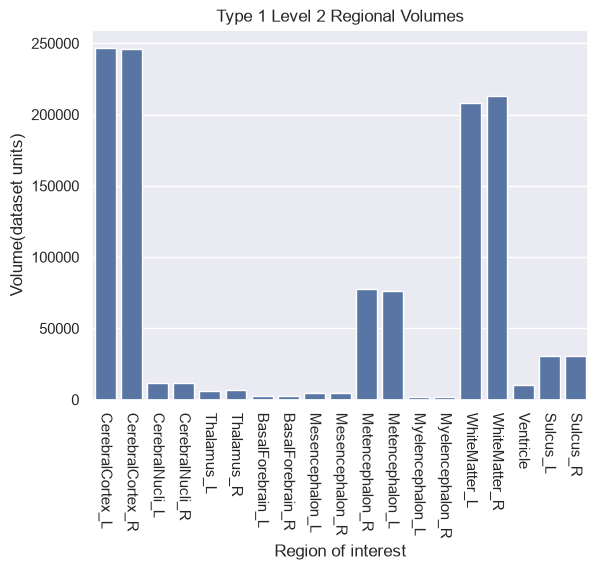

In [ ]:
#problem 3
type1_level2=kirby906a_ax_df.loc[(kirby906a_ax_df["type"]==1) & (kirby906a_ax_df["level"]==2)] #also you could add .sort("volume") so when yuo plot it could show from lowest to larget volumes
sns.barplot(x="roi", y="volume", data=type1_level2)
plt.xticks(rotation=-90) # make the roi rotate clockwise by 90 degree
plt.xlabel("Region of interest")
plt.ylabel("Volume(dataset units)")
plt.title("Type 1 Level 2 Regional Volumes")

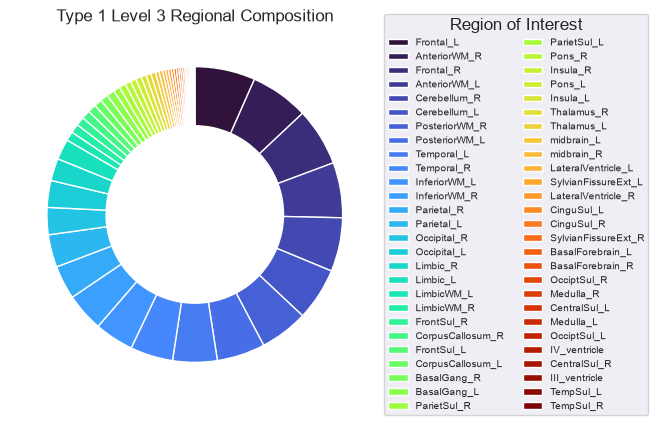

In [29]:
#problem 4
type1_level3=kirby906a_ax_df.loc[(kirby906a_ax_df['type']==1) & (kirby906a_ax_df['level']==3)].sort_values("volume", ascending=False)
# the .sort() fucntion useful in recognizing the order of fraction in a donut plot from largest to smallest or smallest to lag=rgest 
colors=plt.cm.turbo(np.linspace(0, 1, len(type1_level3)))
# len(type1_level3) counts the rows, 54 regions
#np.linspace(0, 1, 54), create 54 evenly spaced numbers from 0 to 1, recall donut plot has the concept of fraction, so we use 0 to 1
#plt.cm.turbo() looks up a color for each of these numbers in matplotlib's turbo color map
wedges, texts=plt.pie(type1_level3['volume'], colors=colors, startangle=90, counterclock=False, wedgeprops={"width":0.4},)
# the plt.pie() always return 2 values the first is the plot, the second is only for receiveing unused tet subjects
#the startangle=90 set the starting point for drawing the slices, the wedgegroups+{"width": 0.4} sets the thickness of the wedge to 0.4 with default outer radius 1.0 inner radius 0.6
# if you want the slices with their associated 'roi' shown directely next to the slices without creating  a legend try the commands below
# plt.pie(type1_level3['volume'], labels=type1_level3['roi'], wedge groups={"width":0.4})
plt.legend(wedges, type1_level3["roi"], title="Region of Interest", loc="center left", bbox_to_anchor=(1,0.5), ncol=2, fontsize=7)
#use wedges which return the plot to use as the data for legend, and pair with the corresponding 'roi'.
#loc="center left" picks the middle of the legend's left edge as its attachment point 
#bbox_to_anchor=(1,0.5) puts that point at the right edge of the plotting area, halfway up which together with the loc puts the legend to the right of the donut
plt.title("Type 1 Level 3 Regional Composition")
plt.show()

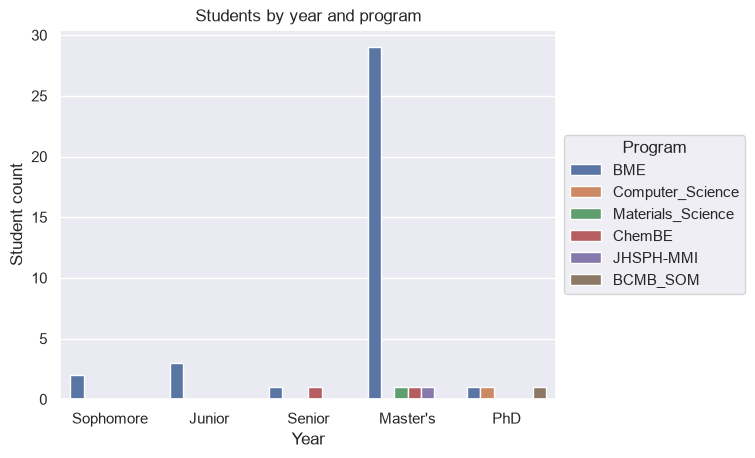

In [15]:
#probelm 5
class_url="https://raw.githubusercontent.com/bcaffo/ds4ph-bme/refs/heads/master/data/classInterests.txt"
class_interests_df=pd.read_csv(class_url, sep='\t') #pd.read_csv is capable to also read txt file but need to menetioned what separates the columns
# for this problem the 2 colums is seperated by tab so we add sep-'\t'), if the columns seperated by comma, no need to do anything 
# why beacuse csv stands for comma seperated values 
# if columns seperated by one or more than one spaces, add r="\s+")
sns.countplot(data=class_interests_df, x='Year', hue='Program', order=["Sophomore", "Junior", "Senior", "Master's", "PhD"])
#This is different from previous questions with bar plots they already have a number , hue='program' seperates the Year further by program, order display the year in a specific order
plt.ylabel("Student count")
plt.title("Students by year and program")
plt.legend(title="Program", loc="center left", bbox_to_anchor=(1,0.5))
plt.show()


In [21]:
#probelm 6
gene_expression_url="https://raw.githubusercontent.com/jhu-advdatasci/2018/refs/heads/master/data/GSE5859_exprs.csv"
gene_expression_df = pd.read_csv(gene_expression_url, index_col=0) #inddex_col=0 tell pandas to use first csv columns as the row labels
sample_info_url="https://raw.githubusercontent.com/jhu-advdatasci/2018/refs/heads/master/data/GSE5859_sampleinfo.csv"
sample_info_df=pd.read_csv(sample_info_url)

#step 1: subrtract the rowean from each row 
row_means=gene_expression_df.mean(axis=1) #goes across the columns and returns one mean per row
#very important in pandas, axis=1 means the row axis and axis=0 means the column axis
gene_expression_df_pt1=gene_expression_df.sub(row_means, axis="index") #matches each mean to its row label 

#step 2: taking matrix after step 1 and subtract the column mean from each column
column_means=gene_expression_df_pt1.mean(axis=0) #goes across the rows and returns one mean per column
gene_expression_df_pt2=gene_expression_df_pt1.sub(column_means, axis="columns") #matches each mean to its column label

#step 3: 
column_stds=gene_expression_df_pt2.std(axis=0, ddof=1) #goes across the rows  and returns one std per column, ddof=1 do the sample standard deviation
gene_expression_df_pt3= gene_expression_df_pt2.div(column_stds, axis="columns") #matches each std to its column label

print("Matrix Shape:", gene_expression_df_pt3.shape) #check the size of matrix after step 3
print("All sample names match:", set(gene_expression_df.columns) == set(sample_info_df['filename']))
print("step 1 row means are near 0:", np.allclose(gene_expression_df_pt1.mean(axis=1), 0))
#check if the operations in step 1 is successfully completed 
#np.allclose() fucntion checks if a subject's value is close to an assigned value, can allow small difference 
# how far could it be to still counted as "close"? Ans: abs(a - b) <= 1e-8 + 1e-5 * abs(b)
print("step 2 column means are near 0:", np.allclose(gene_expression_df_pt2.mean(axis=0), 0))
#check if the operation in step 2 is successfully completed 
print("step 3 column standard deviations are near 1:", np.allclose(gene_expression_df_pt3.std(axis=0, ddof=1), 1))



Matrix Shape: (8793, 208)
All sample names match: True
step 1 row means are near 0: True
step 2 column means are near 0: True
step 3 column standard deviations are near 1: True


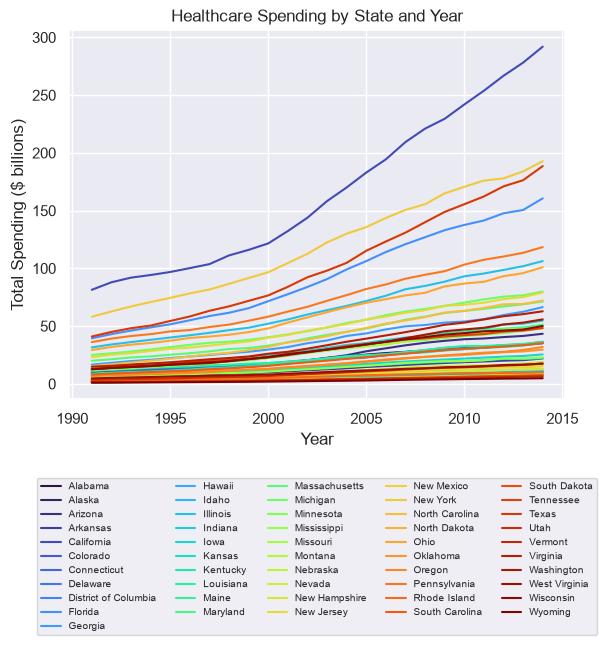

In [27]:
#problem 7
healthcare_url="https://raw.githubusercontent.com/jhu-advdatasci/2018/master/data/KFF/healthcare-spending.csv"
healthcare_df=pd.read_csv(healthcare_url, skiprows=2, nrows=52) #skip the 2 metadata lines and read the 52 rows before the notes
state_spending=healthcare_df.set_index('Location').drop(index='United States') #make the state names the row labels and drop "United States"
state_spending.columns=state_spending.columns.str.split("__").str[0].astype(int)
#The original year columns has something like "1991__Total Health Spending" .split("__") split the string into 2 parts
#str[0] keeps the year, .astype(int) convert the string "1991" to int 1911
(state_spending.T / 1000).plot(colormap='turbo', legend=False) 
#Transpose the row to column and column to rows, so the year(rows) will be x-axis and spedning (/1000 in billion) will be y-axis
plt.xlabel("Year")
plt.ylabel("Total Spending ($ billions)")
plt.title("Healthcare Spending by State and Year")
plt.legend(loc="upper center", bbox_to_anchor=(0.5,-0.2), ncol=5, fontsize=7)
#pick the upper center part of the legend as the attachment point 
#bbox_to_anchor=(0.5,-0.2) 0.5 is half way from the left edge to the right edge, -0.2 is 20% of the plot height below bottom of the plot edge
#together make the legend centered horizontally below the plot
# ncol=52 create 5 columns for the states legend
plt.show()


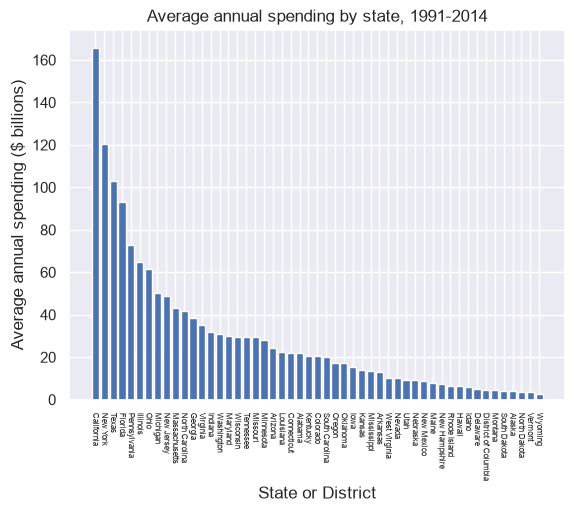

In [28]:
#problem 8
average_spending=state_spending.mean(axis=1).sort_values(ascending=False)
#create the average spending (annual) per state (row) and make the order of the row by desceding values from largest to smallest
plt.bar(x=average_spending.index, height=average_spending/1000) #can also omit the x= and height= will automatically assign, unless otherwise specified
# x is the state name on x-axis, height is the y-value the average annual spending of corresponding state
plt.xticks(rotation=-90, fontsize=6) #make the state name turn -90 degree (90 degree clockwise)
plt.xlabel("State or District")
plt.ylabel("Average annual spending ($ billions)")
plt.title("Average annual spending by state, 1991-2014")
plt.show()